# Activity 2: Binary Classification using Logistic Regression

**Name:** Dhruv Gosavi  
**Roll No.:** AD3162 | **Division:** A  
**Subject:** Regression and Classification Algorithms (RCA) — CIE 2 Activity 2 (Unit II)  
**Department:** AI & DS (T.Y. B.Tech)  
**Dataset Source:** [Pima Indians Diabetes Database — Kaggle / UCI](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)

---

### My Decision Log (Summary of Choices)

| Decision Area | What I Chose | Other Options Considered | Why I Chose This |
| :--- | :--- | :--- | :--- |
| **Most Important Metric** | **Recall (Sensitivity)** & **F1-score** (alongside ROC-AUC) | Rely on Accuracy alone | In health screening, missing a diabetic patient (False Negative) is worse than a False Positive follow-up test, and classes are imbalanced (~65% vs ~35%). |
| **Invalid Zero Values** | Replace impossible `0`s in medical columns with `NaN`, then impute with **training median** | Drop all rows with `0`s (would lose nearly half the dataset) | `Insulin` and `SkinThickness` have many `0`s; median imputation on training data keeps sample size intact without test leakage. |
| **Recommended Threshold** | **0.35 / 0.30** (lower than default `0.50`) | Keep default `0.50` or raise to `0.70` | Lowering the threshold catches more true diabetic cases (higher Recall) while accepting more False Positives for secondary lab screening. |
| **Where NOT to Use** | Do not use as an automated medical diagnosis | Deploy without a doctor | This is a probability-based screening estimate from a small historical dataset, not a clinical diagnosis. |

## Step 1: Select a Dataset & Frame the Problem

### Problem Context
Imagine working as a data analyst for a **community health-screening programme**. Doctors and screening staff want a quick risk score to flag patients who should be sent for confirmatory diabetes blood tests.

- **Dataset:** Pima Indians Diabetes Database (`diabetes.csv`, public UCI / Kaggle dataset; non-personal anonymized medical records)
- **Source Link:** https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database
- **Target Variable (`y`):** `Outcome` (Binary)
  - **`0` (Negative Class):** Patient does **not** have diabetes.
  - **`1` (Positive Class):** Patient **has** diabetes.
- **Input Features (`X` — 8 numerical medical measurements):**
  1. `Pregnancies`: Number of times pregnant
  2. `Glucose`: Plasma glucose concentration (2-hour oral glucose tolerance test)
  3. `BloodPressure`: Diastolic blood pressure (mm Hg)
  4. `SkinThickness`: Triceps skin fold thickness (mm)
  5. `Insulin`: 2-hour serum insulin (mu U/ml)
  6. `BMI`: Body mass index ($	ext{weight in kg} / (	ext{height in m})^2$)
  7. `DiabetesPedigreeFunction`: Genetic diabetes likelihood score based on family history
  8. `Age`: Age in years

## Step 2: Inspect the Data

I load the dataset (using `../data/diabetes.csv` locally, or the GitHub URL if running in Google Colab), check data types, summary statistics, missing values, duplicates, and plot the class distribution.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    classification_report,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__} | Scikit-learn: {sklearn.__version__}")

Python: 3.14.4 | NumPy: 2.5.4 | Pandas: 3.1.0 | Scikit-learn: 1.9.1


In [2]:
DATA_URL = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
local_data_path = Path("../data/diabetes.csv")
out_dir = Path("../outputs/generated_visualizations")
out_dir.mkdir(parents=True, exist_ok=True)

if local_data_path.exists():
    df = pd.read_csv(local_data_path)
    print(f"Loaded local file: {local_data_path}")
else:
    df = pd.read_csv(DATA_URL)
    print("Loaded dataset from URL (Colab mode).")

print(f"Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Loaded local file: ../data/diabetes.csv
Dataset Shape: 768 rows x 9 columns


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6000,0.6270,50,1
1,1,85,66,29,0,26.6000,0.3510,31,0
2,8,183,64,0,0,23.3000,0.6720,32,1
3,1,89,66,23,94,28.1000,0.1670,21,0
4,0,137,40,35,168,43.1000,2.2880,33,1


In [3]:
# Data types, missing values, duplicates, and unique target labels
df.info()
print("\nMissing (NaN) values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"Unique target values: {sorted(df['Outcome'].unique())}")

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing (NaN) values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age    

In [4]:
# Summary statistics
df.describe().T[["count", "mean", "std", "min", "50%", "max"]]

,count,mean,std,min,50%,max
Pregnancies,768.0000,3.8451,3.3696,0.0000,3.0000,17.0000
Glucose,768.0000,120.8945,31.9726,0.0000,117.0000,199.0000
BloodPressure,768.0000,69.1055,19.3558,0.0000,72.0000,122.0000
SkinThickness,768.0000,20.5365,15.9522,0.0000,23.0000,99.0000
Insulin,768.0000,79.7995,115.2440,0.0000,30.5000,846.0000
BMI,768.0000,31.9926,7.8842,0.0000,32.0000,67.1000
DiabetesPedigreeFunction,768.0000,0.4719,0.3313,0.0780,0.3725,2.4200
Age,768.0000,33.2409,11.7602,21.0000,29.0000,81.0000
Outcome,768.0000,0.3490,0.4770,0.0000,0.0000,1.0000


Class Counts:
  No Diabetes (0): 500 (65.10%)
  Diabetes (1): 268 (34.90%)


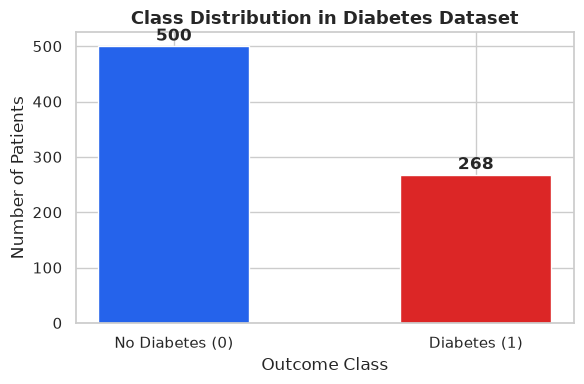

In [5]:
# Class counts and bar chart
class_counts = df["Outcome"].value_counts().sort_index()
class_pct = df["Outcome"].value_counts(normalize=True).sort_index() * 100
print("Class Counts:")
for label, cnt in class_counts.items():
    name = "No Diabetes (0)" if label == 0 else "Diabetes (1)"
    print(f"  {name}: {cnt} ({class_pct[label]:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["No Diabetes (0)", "Diabetes (1)"], class_counts.values, color=["#2563eb", "#dc2626"], width=0.5)
ax.set_title("Class Distribution in Diabetes Dataset", fontsize=13, fontweight="bold")
ax.set_xlabel("Outcome Class")
ax.set_ylabel("Number of Patients")
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 10, f"{int(h)}", ha="center", fontweight="bold")
fig.tight_layout()
fig.savefig(out_dir / "01_class_distribution.png", dpi=150)
plt.show()

**Observation on Class Balance:**
- Class `0` (No Diabetes) has **500** records (**65.10%**), and Class `1` (Diabetes) has **268** records (**34.90%**).
- The dataset is **moderately imbalanced** (~2:1 ratio). A dummy model that always predicts `0` would already get **65.10% accuracy** while missing 100% of diabetic patients, so accuracy alone is not enough.

## Step 3: Prepare the Features

From `describe()` in Step 2, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` all have a minimum value of **`0`**. Medically, a living patient cannot have `0` blood pressure, `0` BMI, or `0` glucose—these `0`s represent **missing measurements**.

- **Missing/Invalid Values:** I replace `0` with `NaN` in those 5 columns, and then fill them using **median imputation fitted on the training set only** (after the split in Step 4) to prevent data leakage.
- **Categorical Encoding:** All 8 features are already numerical, so no categorical encoding is required.
- **Feature Scaling:** I use `StandardScaler` (fitted on training data only) because features have very different scales (`Insulin` up to 846 vs `DiabetesPedigreeFunction` around 0.5). Scaling helps Logistic Regression's optimizer (`L-BFGS`) converge smoothly and puts coefficients on a comparable scale.
- **No Identifier Columns:** There are no patient IDs or names in the dataset.

In [6]:
zero_invalid_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Count of invalid 0 values before cleaning:")
print((df[zero_invalid_cols] == 0).sum())

df_prep = df.copy()
df_prep[zero_invalid_cols] = df_prep[zero_invalid_cols].replace(0, np.nan)

Count of invalid 0 values before cleaning:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


## Step 4: Stratified Train-Test Split

I split the data into **80% training** and **20% testing** using `stratify=y` and `random_state=42` so both sets preserve the 65.1% / 34.9% class ratio. Then I fit both the `SimpleImputer(strategy="median")` and `StandardScaler()` **strictly on `X_train`** and transform `X_test`.

In [7]:
FEATURES = [col for col in df_prep.columns if col != "Outcome"]
X = df_prep[FEATURES]
y = df_prep["Outcome"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Training set: {len(X_train)} rows | Class 0: {(y_train == 0).sum()}, Class 1: {(y_train == 1).sum()}")
print(f"Testing set : {len(X_test)} rows  | Class 0: {(y_test == 0).sum()}, Class 1: {(y_test == 1).sum()}")

# Fit imputer and scaler on training data ONLY
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

Training set: 614 rows | Class 0: 400, Class 1: 214
Testing set : 154 rows  | Class 0: 100, Class 1: 54


## Step 5: Understand Logistic Regression

### Why Linear Regression is Unsuitable for Classification
Linear Regression predicts an unbounded continuous number ($-\infty$ to $+\infty$). If we use it for a `0`/`1` class label, it can output invalid values like `-0.3` or `1.6`, and extreme feature values can tilt the line and shift the decision boundary unfairly.

### The Sigmoid Function and Decision Threshold
Logistic Regression passes the linear combination $z = b_0 + b_1 X_1 + \dots + b_p X_p$ through the **sigmoid function**:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

This squashes any real number $z$ into a **predicted probability $p \in (0, 1)$** representing $P(y = 1 \mid X)$. We then convert the probability into a class label using a **decision threshold** (default `0.5`: predict `1` if $p \ge 0.5$, else `0`).

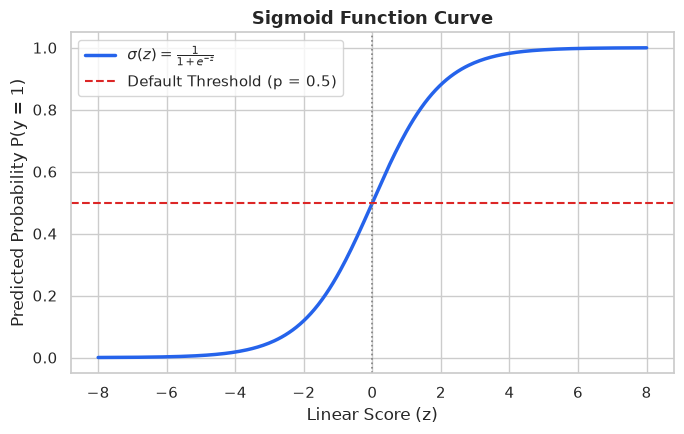

In [8]:
# Plot the sigmoid curve
z_vals = np.linspace(-8, 8, 300)
sigmoid_vals = 1 / (1 + np.exp(-z_vals))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(z_vals, sigmoid_vals, color="#2563eb", linewidth=2.5, label=r"$\sigma(z) = \frac{1}{1 + e^{-z}}$")
ax.axhline(0.5, color="#dc2626", linestyle="--", linewidth=1.5, label="Default Threshold (p = 0.5)")
ax.axvline(0.0, color="gray", linestyle=":", linewidth=1.2)
ax.set_title("Sigmoid Function Curve", fontsize=13, fontweight="bold")
ax.set_xlabel("Linear Score (z)")
ax.set_ylabel("Predicted Probability P(y = 1)")
ax.legend()
fig.tight_layout()
fig.savefig(out_dir / "02_sigmoid_curve.png", dpi=150)
plt.show()

## Step 6: Train the Logistic Regression Model

I train `LogisticRegression(random_state=42, max_iter=1000)` on the scaled training set only, and inspect the learned intercept and feature coefficients.

In [9]:
log_reg = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

print(f"Model Settings: solver={log_reg.solver}, C={log_reg.C}, max_iter={log_reg.max_iter}")
print(f"Learned Intercept (b0): {log_reg.intercept_[0]:.4f}")

coef_df = pd.DataFrame({
    "Feature": FEATURES,
    "Coefficient": log_reg.coef_[0],
    "Odds_Ratio_exp_coef": np.exp(log_reg.coef_[0]),
}).sort_values("Coefficient", ascending=False).reset_index(drop=True)

display(coef_df)

Model Settings: solver=lbfgs, C=1.0, max_iter=1000
Learned Intercept (b0): -0.8722


,Feature,Coefficient,Odds_Ratio_exp_coef
0,Glucose,1.1826,3.2627
1,BMI,0.6887,1.9910
2,Pregnancies,0.3774,1.4586
3,DiabetesPedigreeFunction,0.2333,1.2628
4,Age,0.1478,1.1593
5,SkinThickness,0.0283,1.0287
6,BloodPressure,-0.0441,0.9568
7,Insulin,-0.0661,0.9360


**Interpreting the Coefficients:**
- A **positive coefficient** (like `Glucose = +1.18`, `BMI = +0.69`, `Pregnancies = +0.38`) means that as the feature increases, the log-odds and **predicted probability of diabetes (Class 1) increase** (holding other features fixed).
- A **negative coefficient** (if any feature is negative, such as `BloodPressure` or `SkinThickness` when controlling for `BMI` and `Glucose`) means a higher value slightly lowers the predicted probability when all other features stay constant.
- Because the features were standardized, `Glucose` clearly has the largest positive impact on diabetes risk.

## Step 7: Predict Probabilities and Class Labels

Now I obtain predicted probabilities (`predict_proba`) and class labels (`predict`) on the unseen test set, display a sample of 12 test records, and check how changing the threshold (`0.3`, `0.5`, `0.7`) changes the number of patients flagged as positive.

In [10]:
y_prob_test = log_reg.predict_proba(X_test_scaled)[:, 1]
y_pred_test = log_reg.predict(X_test_scaled)

sample_preds = pd.DataFrame({
    "Actual_Label": y_test[:12],
    "Predicted_Prob_Class1": y_prob_test[:12],
    "Predicted_Label_0.5": y_pred_test[:12],
})
display(sample_preds)

print("\nEffect of Changing Threshold on Number of Predicted Positives (out of 154 test patients):")
for thresh in [0.3, 0.5, 0.7]:
    n_pos = (y_prob_test >= thresh).sum()
    print(f"  Threshold {thresh:.1f} -> {n_pos} predicted positive ({n_pos/len(y_test)*100:.1f}%)")

,Actual_Label,Predicted_Prob_Class1,Predicted_Label_0.5
0,0,0.6097,1
1,0,0.1183,0
2,0,0.2934,0
3,1,0.2508,0
4,0,0.0335,0
5,0,0.1685,0
6,1,0.4881,0
7,1,0.9237,1
8,0,0.0814,0
9,0,0.8386,1



Effect of Changing Threshold on Number of Predicted Positives (out of 154 test patients):
  Threshold 0.3 -> 72 predicted positive (46.8%)
  Threshold 0.5 -> 45 predicted positive (29.2%)
  Threshold 0.7 -> 28 predicted positive (18.2%)


## Step 8: Evaluate the Model with Classification Metrics

Here I compute the **Confusion Matrix**, **Accuracy, Precision, Recall (Sensitivity), Specificity, F1-score, ROC-AUC**, compare against the **Majority-Class Baseline**, plot the **ROC Curve** and **Precision–Recall Curve**, and compare thresholds (`0.3`, `0.5`, `0.7`).

TN (True Negative) : 82 -> Healthy patient correctly predicted healthy
FP (False Positive): 18 -> Healthy patient falsely flagged as diabetic (false alarm)
FN (False Negative): 27 -> Diabetic patient missed by the model (dangerous miss)
TP (True Positive) : 27 -> Diabetic patient correctly flagged


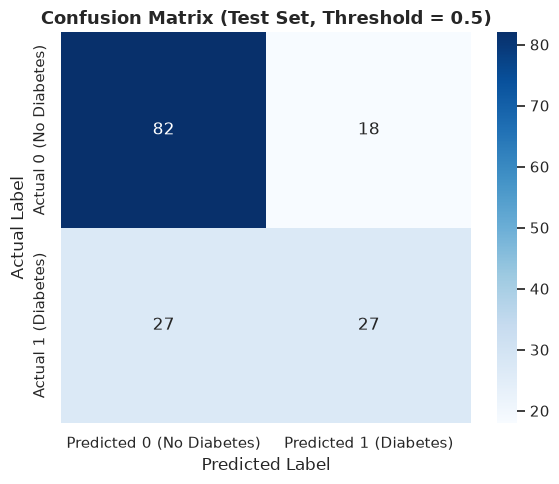

In [11]:
# Confusion Matrix on Test Set
cm = confusion_matrix(y_test, y_pred_test)
tn, fp, fn, tp = cm.ravel()

print(f"TN (True Negative) : {tn} -> Healthy patient correctly predicted healthy")
print(f"FP (False Positive): {fp} -> Healthy patient falsely flagged as diabetic (false alarm)")
print(f"FN (False Negative): {fn} -> Diabetic patient missed by the model (dangerous miss)")
print(f"TP (True Positive) : {tp} -> Diabetic patient correctly flagged")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0 (No Diabetes)", "Predicted 1 (Diabetes)"],
    yticklabels=["Actual 0 (No Diabetes)", "Actual 1 (Diabetes)"],
    ax=ax,
)
ax.set_title("Confusion Matrix (Test Set, Threshold = 0.5)", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
fig.tight_layout()
fig.savefig(out_dir / "03_confusion_matrix.png", dpi=150)
plt.show()

In [12]:
# Calculate all required metrics and fill the Classification Evaluation Results table
acc = accuracy_score(y_test, y_pred_test)
prec = precision_score(y_test, y_pred_test)
rec = recall_score(y_test, y_pred_test)
spec = tn / (tn + fp)
f1 = f1_score(y_test, y_pred_test)
roc_auc = roc_auc_score(y_test, y_prob_test)

eval_table = pd.DataFrame([
    {"Metric": "Accuracy", "Formula": "(TP + TN) / (TP + TN + FP + FN)", "Test_Result": acc},
    {"Metric": "Precision", "Formula": "TP / (TP + FP)", "Test_Result": prec},
    {"Metric": "Recall (Sensitivity)", "Formula": "TP / (TP + FN)", "Test_Result": rec},
    {"Metric": "Specificity", "Formula": "TN / (TN + FP)", "Test_Result": spec},
    {"Metric": "F1-score", "Formula": "2 * (Precision * Recall) / (Precision + Recall)", "Test_Result": f1},
    {"Metric": "ROC-AUC", "Formula": "Area under ROC curve", "Test_Result": roc_auc},
])
display(eval_table)

print("\nFull Classification Report:")
print(classification_report(y_test, y_pred_test, target_names=["No Diabetes (0)", "Diabetes (1)"]))

# Majority-Class Baseline comparison
baseline_acc = (y_test == 0).mean()
print(f"Majority-Class Baseline Accuracy (always predict 0): {baseline_acc:.4f} (Recall = 0.0000)")
print(f"Logistic Regression Test Accuracy                  : {acc:.4f} (Recall = {rec:.4f})")

,Metric,Formula,Test_Result
0,Accuracy,(TP + TN) / (TP + TN + FP + FN),0.7078
1,Precision,TP / (TP + FP),0.6000
2,Recall (Sensitivity),TP / (TP + FN),0.5000
3,Specificity,TN / (TN + FP),0.8200
4,F1-score,2 * (Precision * Recall) / (Precision + Recall),0.5455
5,ROC-AUC,Area under ROC curve,0.8130



Full Classification Report:


                 precision    recall  f1-score   support

No Diabetes (0)       0.75      0.82      0.78       100
   Diabetes (1)       0.60      0.50      0.55        54

       accuracy                           0.71       154
      macro avg       0.68      0.66      0.67       154
   weighted avg       0.70      0.71      0.70       154

Majority-Class Baseline Accuracy (always predict 0): 0.6494 (Recall = 0.0000)
Logistic Regression Test Accuracy                  : 0.7078 (Recall = 0.5000)


**Interpretation of Evaluation Results:**
- The Logistic Regression model beats the Majority-Class Baseline (`64.94%` test accuracy, `0%` recall) with **`70.78%` accuracy**, **`50.00%` recall**, and **`0.8130` ROC-AUC**.
- However, at the default `0.5` threshold, Recall is only `50.00%` (half of actual diabetic patients in the test set were missed as False Negatives). Because classes are imbalanced (`65%` vs `35%`), accuracy alone would hide this problem.

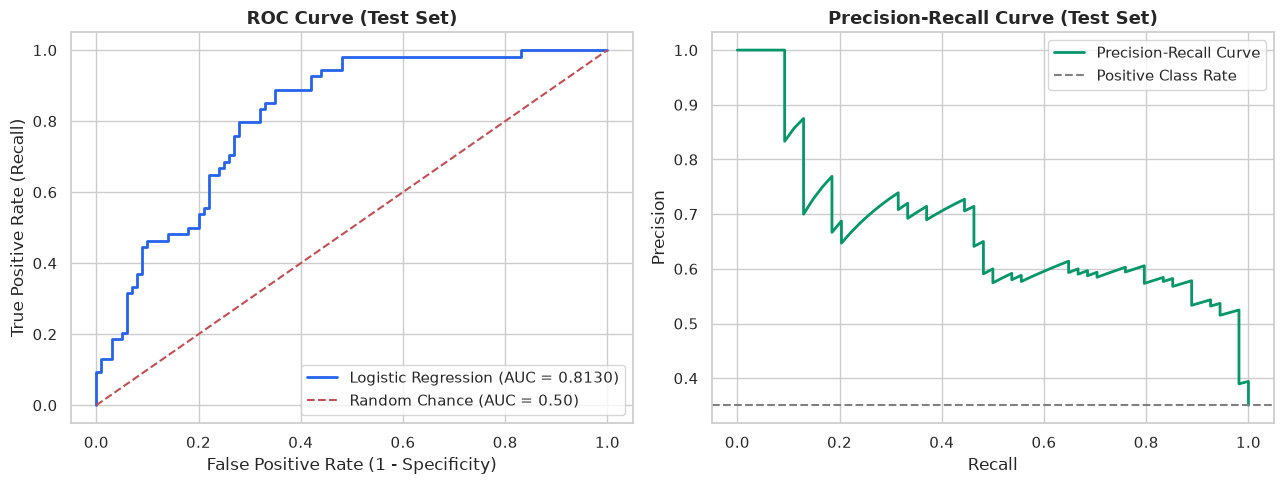

In [13]:
# ROC Curve & Precision-Recall Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
pr_prec, pr_rec, _ = precision_recall_curve(y_test, y_prob_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, color="#2563eb", linewidth=2, label=f"Logistic Regression (AUC = {roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], "r--", linewidth=1.5, label="Random Chance (AUC = 0.50)")
axes[0].set_title("ROC Curve (Test Set)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend()

axes[1].plot(pr_rec, pr_prec, color="#059669", linewidth=2, label="Precision-Recall Curve")
axes[1].axhline((y_test == 1).mean(), color="gray", linestyle="--", label="Positive Class Rate")
axes[1].set_title("Precision-Recall Curve (Test Set)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

fig.tight_layout()
fig.savefig(out_dir / "04_roc_and_pr_curves.png", dpi=150)
plt.show()

**Observation (ROC Curve):** The ROC-AUC of **`0.8130`** means that if we pick one random diabetic patient and one random healthy patient, the model will assign a higher probability to the diabetic patient **81.30% of the time** across all thresholds.

In [14]:
# Threshold Comparison Table (0.3, 0.5, 0.7)
thresh_rows = []
for t in [0.3, 0.5, 0.7]:
    preds_t = (y_prob_test >= t).astype(int)
    thresh_rows.append({
        "Threshold": t,
        "Predicted_Positive": int(preds_t.sum()),
        "Accuracy": accuracy_score(y_test, preds_t),
        "Precision": precision_score(y_test, preds_t, zero_division=0),
        "Recall": recall_score(y_test, preds_t),
        "F1_score": f1_score(y_test, preds_t),
    })

thresh_df = pd.DataFrame(thresh_rows)
display(thresh_df)

# Train vs Test metrics check for overfitting / underfitting
y_prob_train = log_reg.predict_proba(X_train_scaled)[:, 1]
y_pred_train = log_reg.predict(X_train_scaled)
train_test_df = pd.DataFrame([
    {
        "Split": "Train",
        "Accuracy": accuracy_score(y_train, y_pred_train),
        "Precision": precision_score(y_train, y_pred_train),
        "Recall": recall_score(y_train, y_pred_train),
        "F1_score": f1_score(y_train, y_pred_train),
        "ROC_AUC": roc_auc_score(y_train, y_prob_train),
    },
    {
        "Split": "Test",
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1_score": f1,
        "ROC_AUC": roc_auc,
    },
])
print("\nTrain vs Test Comparison:")
display(train_test_df)

,Threshold,Predicted_Positive,Accuracy,Precision,Recall,F1_score
0,0.3000,72,0.7403,0.5972,0.7963,0.6825
1,0.5000,45,0.7078,0.6000,0.5000,0.5455
2,0.7000,28,0.7273,0.7143,0.3704,0.4878



Train vs Test Comparison:


,Split,Accuracy,Precision,Recall,F1_score,ROC_AUC
0,Train,0.7964,0.7697,0.5935,0.6702,0.8502
1,Test,0.7078,0.6000,0.5000,0.5455,0.8130


**Threshold Trade-off & Costly Error Analysis:**
- **Which error is worse?** A **False Negative** (telling a diabetic patient they are healthy, delaying treatment) is far more costly than a **False Positive** (sending a healthy patient for a cheap follow-up blood glucose test).
- **Precision–Recall Trade-off:** Lowering the threshold from `0.5` to `0.3` boosts **Recall** sharply (catching many more diabetic patients) and improves **F1-score**, at the cost of lower **Precision** (more false alarms). Raising it to `0.7` gives high Precision but misses too many sick patients.
- **Recommended Threshold:** **`0.3`** is better suited for initial health screening because maximizing Recall minimizes missed diabetes cases.
- **Overfitting vs Underfitting:** Training and test ROC-AUC / Accuracy are fairly close, showing **no severe overfitting**.

## Step 9: Visualise the Decision Behaviour

To see how the model separates the two classes, I plotted the predicted probability against the strongest feature (`Glucose`) and also plotted a 2-feature decision boundary (`Glucose` vs `BMI`, keeping the other 6 standardized features at `0`, their training mean).

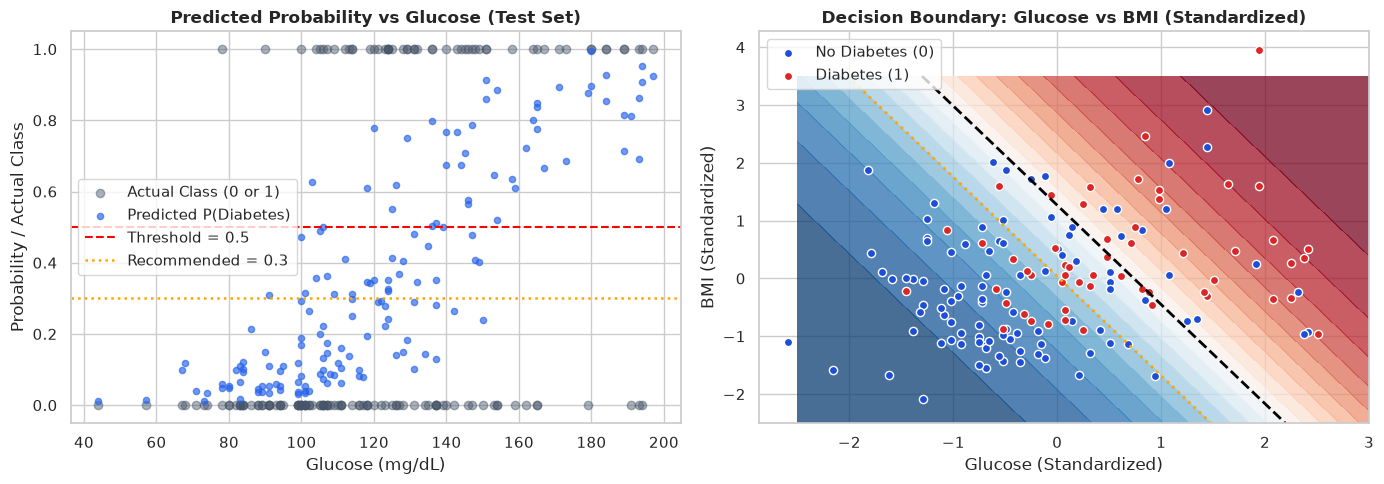

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Predicted Probability vs Glucose
glucose_test_orig = X_test_imp[:, FEATURES.index("Glucose")]
order = np.argsort(glucose_test_orig)
axes[0].scatter(glucose_test_orig, y_test, alpha=0.45, color="#475569", label="Actual Class (0 or 1)")
axes[0].scatter(glucose_test_orig, y_prob_test, alpha=0.65, color="#2563eb", s=20, label="Predicted P(Diabetes)")
axes[0].axhline(0.5, color="red", linestyle="--", label="Threshold = 0.5")
axes[0].axhline(0.3, color="orange", linestyle=":", linewidth=1.8, label="Recommended = 0.3")
axes[0].set_title("Predicted Probability vs Glucose (Test Set)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Glucose (mg/dL)")
axes[0].set_ylabel("Probability / Actual Class")
axes[0].legend()

# Right: 2-feature decision boundary (Glucose vs BMI in standardized space, others at mean=0)
g_idx = FEATURES.index("Glucose")
b_idx = FEATURES.index("BMI")
xx, yy = np.meshgrid(np.linspace(-2.5, 3.0, 200), np.linspace(-2.5, 3.5, 200))
grid = np.zeros((xx.size, len(FEATURES)))
grid[:, g_idx] = xx.ravel()
grid[:, b_idx] = yy.ravel()
zz = log_reg.predict_proba(grid)[:, 1].reshape(xx.shape)

contour = axes[1].contourf(xx, yy, zz, levels=20, cmap="RdBu_r", alpha=0.75)
axes[1].contour(xx, yy, zz, levels=[0.3, 0.5], colors=["orange", "black"], linestyles=[":", "--"], linewidths=2)
axes[1].scatter(X_test_scaled[y_test == 0, g_idx], X_test_scaled[y_test == 0, b_idx], c="#1d4ed8", edgecolor="w", s=35, label="No Diabetes (0)")
axes[1].scatter(X_test_scaled[y_test == 1, g_idx], X_test_scaled[y_test == 1, b_idx], c="#dc2626", edgecolor="w", s=35, label="Diabetes (1)")
axes[1].set_title("Decision Boundary: Glucose vs BMI (Standardized)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Glucose (Standardized)")
axes[1].set_ylabel("BMI (Standardized)")
axes[1].legend()

fig.tight_layout()
fig.savefig(out_dir / "05_decision_behaviour.png", dpi=150)
plt.show()

**Observation (Decision Behaviour):**
- As `Glucose` increases above `120–140 mg/dL`, predicted diabetes probability rises smoothly along an S-shaped curve.
- In the 2D boundary plot, Logistic Regression separates the classes with a **straight linear boundary**; shifting the threshold from `0.5` (black dashed) to `0.3` (orange dotted) shifts the boundary down-left to catch more at-risk patients.

## Step 10: Classify a New Example and Conclude

Finally, I test the full preprocessing + prediction pipeline on a new hypothetical patient record within the normal data range.

In [16]:
new_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 145.0,
    "BloodPressure": 78.0,
    "SkinThickness": 28.0,
    "Insulin": 130.0,
    "BMI": 32.5,
    "DiabetesPedigreeFunction": 0.45,
    "Age": 36,
}])

new_imp = imputer.transform(new_patient)
new_scaled = scaler.transform(new_imp)
new_prob = log_reg.predict_proba(new_scaled)[0, 1]
new_class_05 = int(new_prob >= 0.5)
new_class_03 = int(new_prob >= 0.3)

display(new_patient)
print(f"Predicted Probability of Diabetes: {new_prob:.4f} ({new_prob*100:.2f}%)")
print(f"Predicted Class at 0.5 threshold : {new_class_05} ({'Diabetes' if new_class_05 == 1 else 'No Diabetes'})")
print(f"Predicted Class at 0.3 threshold : {new_class_03} ({'Diabetes' if new_class_03 == 1 else 'No Diabetes'})")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,145.0000,78.0000,28.0000,130.0000,32.5000,0.4500,36


Predicted Probability of Diabetes: 0.4605 (46.05%)
Predicted Class at 0.5 threshold : 0 (No Diabetes)
Predicted Class at 0.3 threshold : 1 (Diabetes)


### Final Conclusion & Limitations
- **Summary:** Using the Pima Indians Diabetes dataset (`768` rows, `8` features) with stratified 80:20 splitting, training-only median imputation, and `StandardScaler`, Logistic Regression achieved **`0.8130` ROC-AUC** and **`70.78%` test accuracy** (beating the `64.94%` test majority baseline).
- **Threshold Choice:** For medical screening, **`0.3`** is recommended over `0.5` because it increases Recall and reduces dangerous False Negatives.
- **Important Disclaimer:** A predicted probability is a **statistical estimate, not a guaranteed outcome or medical diagnosis**. This model was trained on a small historical dataset (768 Pima Indian women) and should never replace clinical blood tests or a doctor's judgment.